In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv(r"C:\Users\Asus\OneDrive\Desktop\datheon task3\Telco-Customer-Churn.csv")


print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Dataset loaded successfully!

Dataset Shape: (7043, 21)

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [5]:


df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("\nAfter Cleaning:")
print(df.isnull().sum().sum())

print("\nData Types:")
print(df.dtypes)

Missing TotalCharges: 0

After Cleaning:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


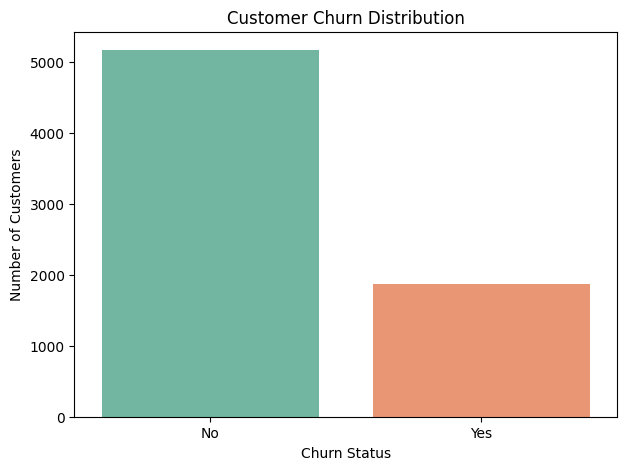

In [6]:


plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

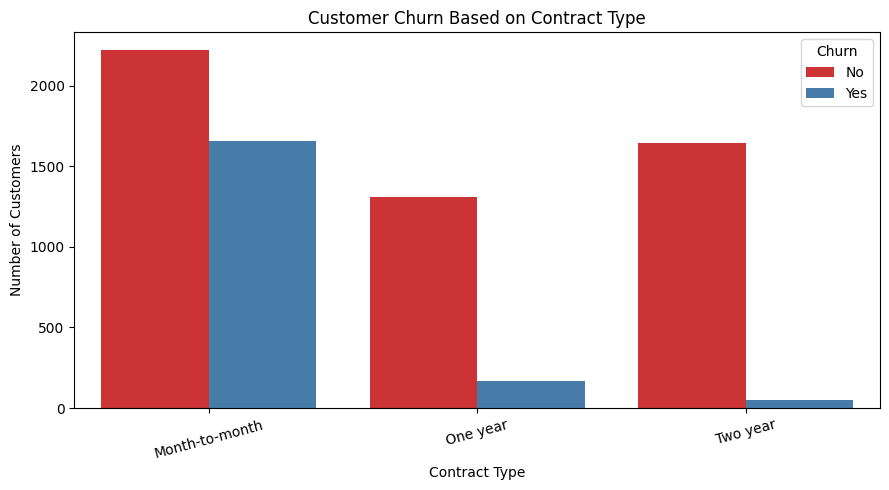

In [7]:
 

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set1"
)

plt.title("Customer Churn Based on Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

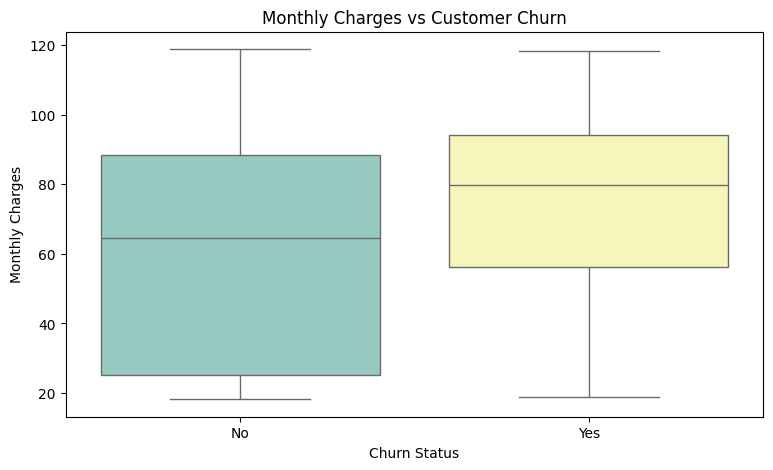

In [8]:


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set3",
    legend=False
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [9]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Customer Churn Percentage:")
print(churn_percentage.round(2))

Customer Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


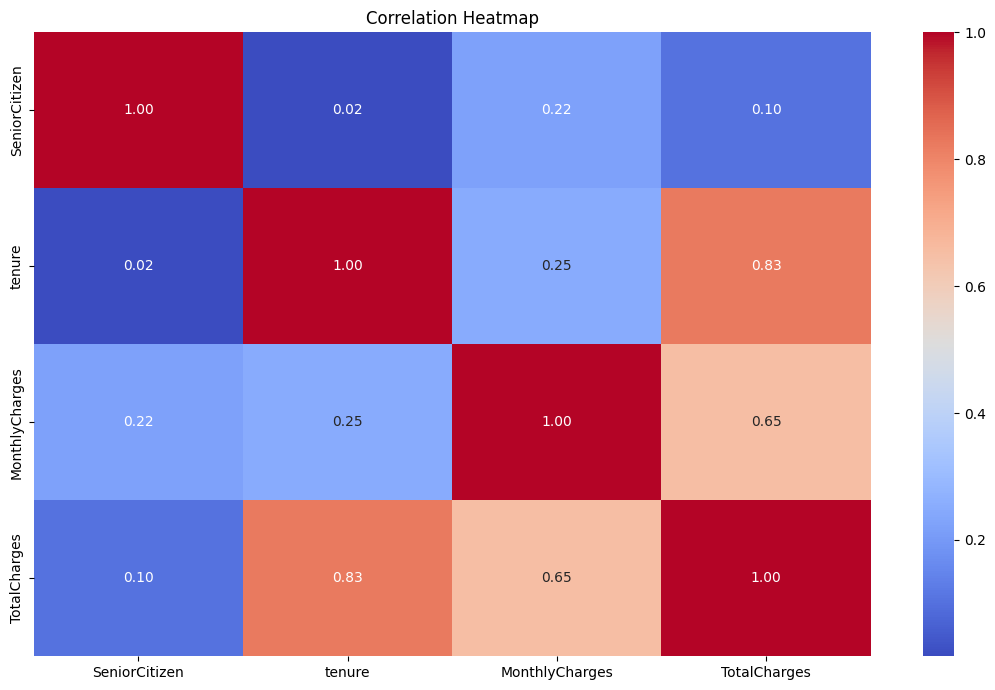

In [10]:
numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 7))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [11]:


df = df.drop("customerID", axis=1)

X = df.drop("Churn", axis=1)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [12]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (5634, 19)
Testing Data: (1409, 19)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer


preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

print("One-Hot Encoding Preprocessor Created Successfully!")

One-Hot Encoding Preprocessor Created Successfully!


In [19]:
import sys

print(sys.executable)

c:\Users\Asus\AppData\Local\Programs\Python\Python314\python.exe


In [22]:
from imblearn.over_sampling import SMOTENC

categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

smote = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTENC:")
print(y_train.value_counts())

print("\nAfter SMOTENC:")
print(y_train_balanced.value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

Before SMOTENC:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTENC:
Churn
0    4139
1    4139
Name: count, dtype: int64

Balanced Training Shape: (8278, 19)


In [23]:


from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)


X_train_encoded = preprocessor.fit_transform(
    X_train_balanced
)


X_test_encoded = preprocessor.transform(
    X_test
)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

print("One-Hot Encoding completed successfully!")

Training data shape: (8278, 45)
Testing data shape: (1409, 45)
One-Hot Encoding completed successfully!


In [24]:


from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)


rf_model.fit(
    X_train_encoded,
    y_train_balanced
)


rf_predictions = rf_model.predict(X_test_encoded)


rf_probabilities = rf_model.predict_proba(
    X_test_encoded
)[:, 1]

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [28]:


from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)


xgb_model.fit(
    X_train_encoded,
    y_train_balanced
)


xgb_predictions = xgb_model.predict(X_test_encoded)

xgb_probabilities = xgb_model.predict_proba(
    X_test_encoded
)[:, 1]

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [29]:


from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(
    rf_model,
    X_train_encoded,
    y_train_balanced,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest Cross-Validation Scores:")
print(rf_cv_scores)

print("Mean ROC-AUC:", rf_cv_scores.mean())

Random Forest Cross-Validation Scores:
[0.91344022 0.92058887 0.92893139 0.92555158 0.91808615]
Mean ROC-AUC: 0.9213196434116113


In [30]:
xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train_encoded,
    y_train_balanced,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("XGBoost Cross-Validation Scores:")
print(xgb_cv_scores)

print("Mean ROC-AUC:", xgb_cv_scores.mean())

XGBoost Cross-Validation Scores:
[0.907686   0.91715238 0.92177326 0.92433363 0.91830667]
Mean ROC-AUC: 0.9178503892059524


In [31]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

rf_pipeline = Pipeline([
    ("smote", SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ("encoder", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline([
    ("smote", SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ("encoder", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

rf_cv_scores = cross_val_score(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

xgb_cv_scores = cross_val_score(
    xgb_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())
print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

Random Forest Mean ROC-AUC: 0.8163130250863373
XGBoost Mean ROC-AUC: 0.8366135667767388


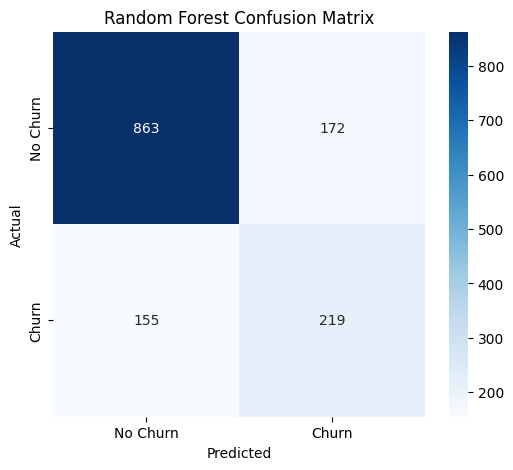

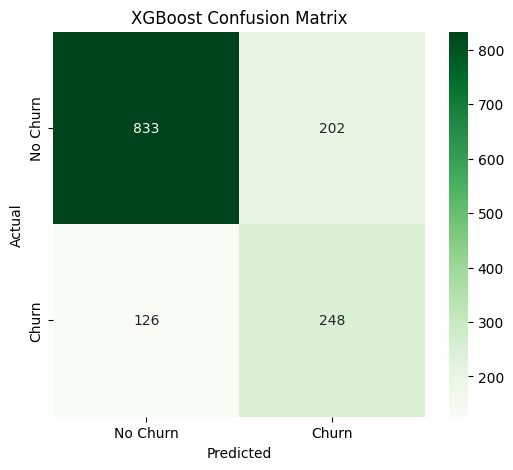

In [32]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



xgb_cm = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

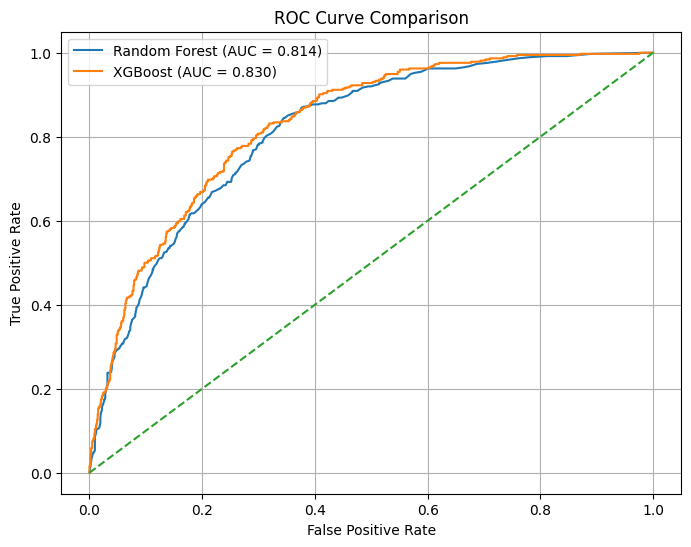

In [33]:
from sklearn.metrics import roc_curve, roc_auc_score

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

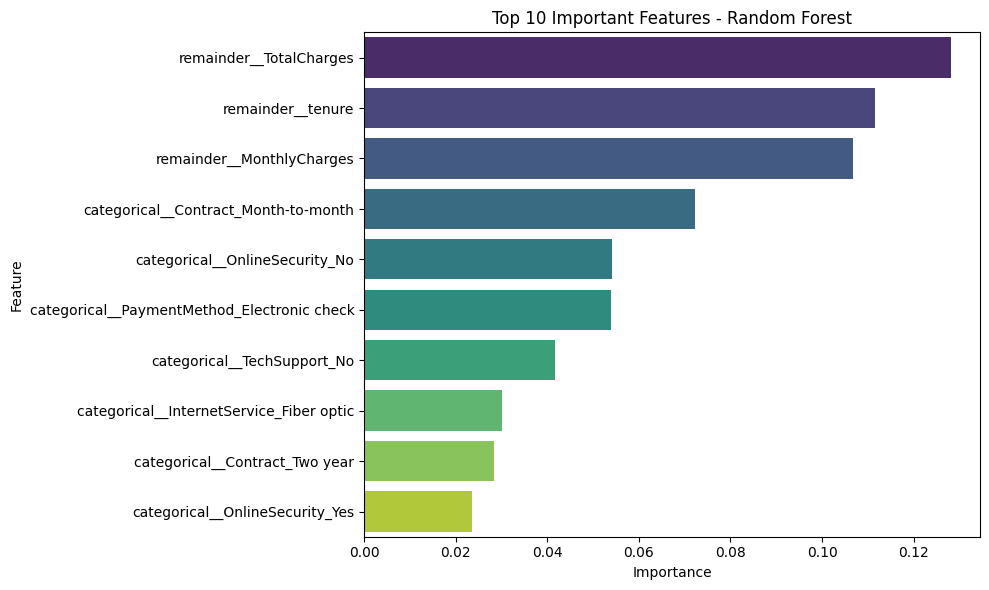

                                        Feature  Importance
44                      remainder__TotalCharges    0.128083
42                            remainder__tenure    0.111485
43                    remainder__MonthlyCharges    0.106657
32         categorical__Contract_Month-to-month    0.072239
14               categorical__OnlineSecurity_No    0.054095
39  categorical__PaymentMethod_Electronic check    0.053910
23                  categorical__TechSupport_No    0.041727
12     categorical__InternetService_Fiber optic    0.030198
34               categorical__Contract_Two year    0.028255
16              categorical__OnlineSecurity_Yes    0.023495


In [34]:


feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Important Features - Random Forest")
plt.tight_layout()
plt.show()

print(rf_importance)

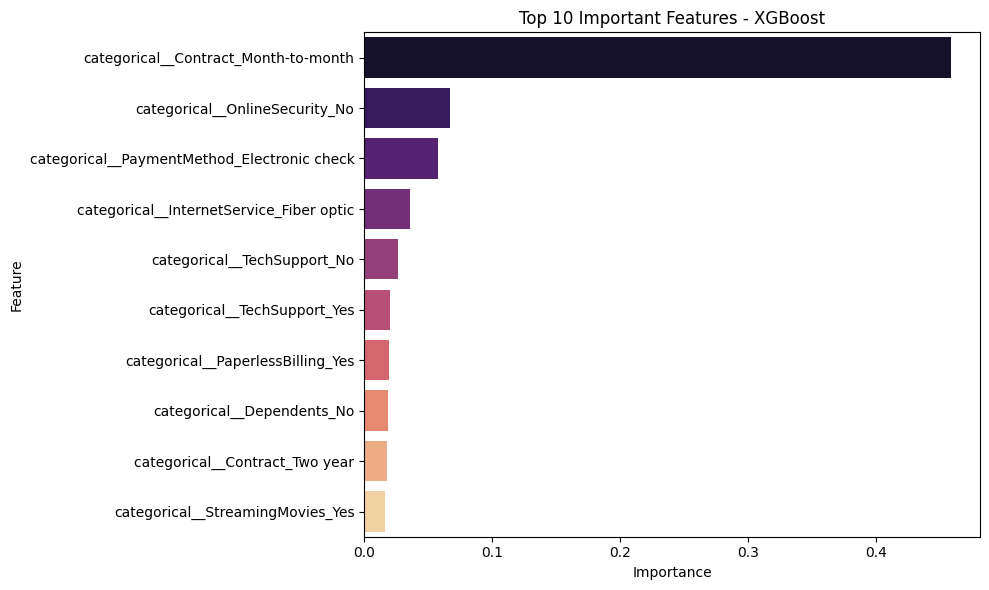

                                        Feature  Importance
32         categorical__Contract_Month-to-month    0.458731
14               categorical__OnlineSecurity_No    0.066863
39  categorical__PaymentMethod_Electronic check    0.057542
12     categorical__InternetService_Fiber optic    0.035618
23                  categorical__TechSupport_No    0.026161
25                 categorical__TechSupport_Yes    0.019997
36            categorical__PaperlessBilling_Yes    0.019373
4                    categorical__Dependents_No    0.018843
34               categorical__Contract_Two year    0.018208
31             categorical__StreamingMovies_Yes    0.016447


In [35]:
xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="magma",
    legend=False
)

plt.title("Top 10 Important Features - XGBoost")
plt.tight_layout()
plt.show()

print(xgb_importance)

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_pipeline = Pipeline([
    ("smote", SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ("encoder", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ))
])

xgb_pipeline = Pipeline([
    ("smote", SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ("encoder", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

rf_cv_scores = cross_val_score(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

xgb_cv_scores = cross_val_score(
    xgb_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc", n_jobs=-1
)

print("Random Forest CV ROC-AUC:", rf_cv_scores)
print("Random Forest Mean:", rf_cv_scores.mean())

print("\nXGBoost CV ROC-AUC:", xgb_cv_scores)
print("XGBoost Mean:", xgb_cv_scores.mean())

Random Forest CV ROC-AUC: [0.81052987 0.80521626 0.81860025 0.81029155 0.8369272 ]
Random Forest Mean: 0.8163130250863373

XGBoost CV ROC-AUC: [0.83001915 0.82530335 0.83324245 0.85012239 0.8443805 ]
XGBoost Mean: 0.8366135667767388


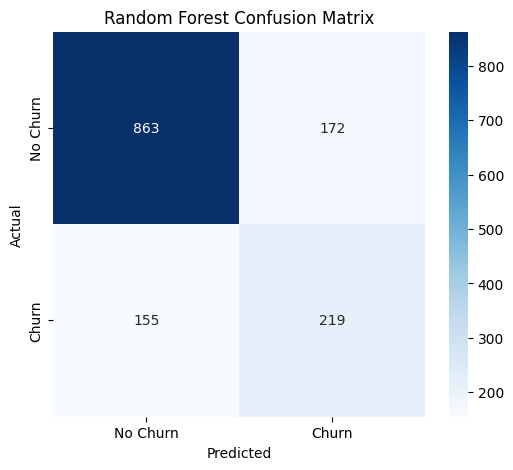

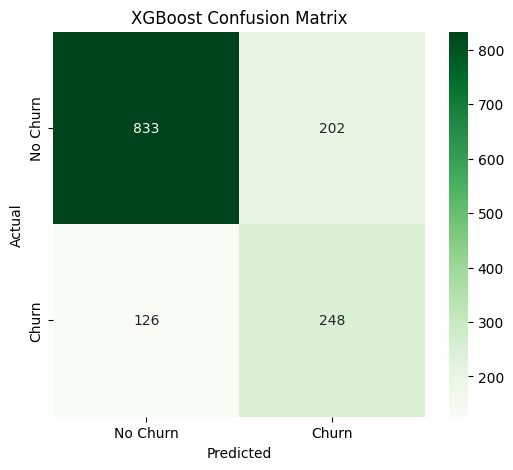

In [37]:
from sklearn.metrics import confusion_matrix


rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


xgb_cm = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

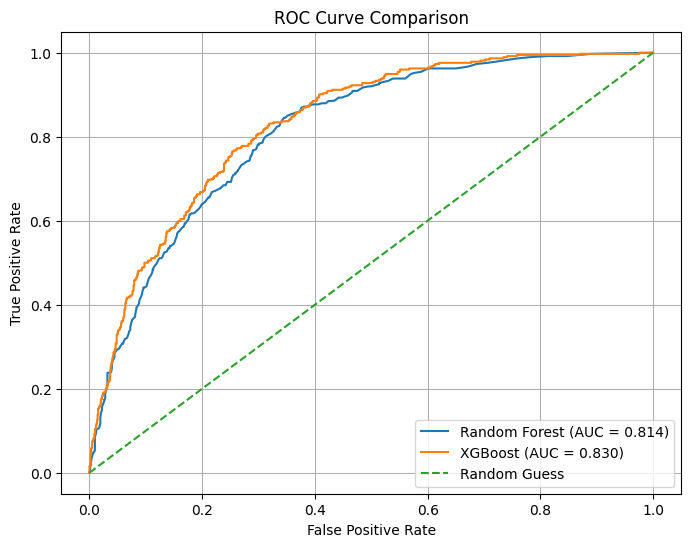

In [38]:
from sklearn.metrics import roc_curve, roc_auc_score


rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)


rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

Random Forest - Top 10 Features


,Feature,Importance
44,remainder__TotalCharges,0.128083
42,remainder__tenure,0.111485
43,remainder__MonthlyCharges,0.106657
32,categorical__Contract_Month-to-month,0.072239
14,categorical__OnlineSecurity_No,0.054095
39,categorical__PaymentMethod_Electronic check,0.053910
23,categorical__TechSupport_No,0.041727
12,categorical__InternetService_Fiber optic,0.030198
34,categorical__Contract_Two year,0.028255
16,categorical__OnlineSecurity_Yes,0.023495


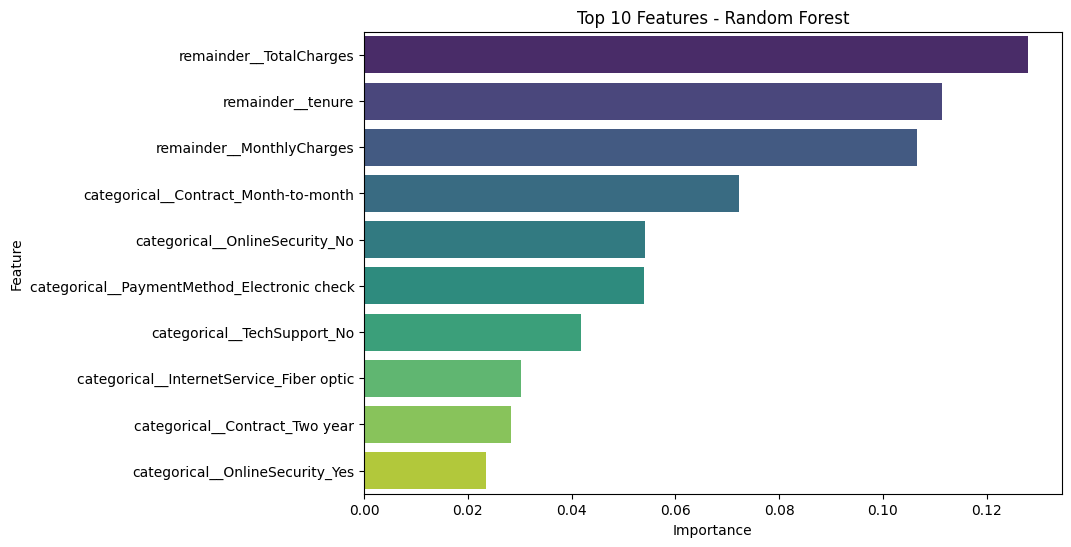

In [39]:

feature_names = preprocessor.get_feature_names_out()


rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print("Random Forest - Top 10 Features")
display(rf_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)
plt.title("Top 10 Features - Random Forest")
plt.show()

XGBoost - Top 10 Features


,Feature,Importance
32,categorical__Contract_Month-to-month,0.458731
14,categorical__OnlineSecurity_No,0.066863
39,categorical__PaymentMethod_Electronic check,0.057542
12,categorical__InternetService_Fiber optic,0.035618
23,categorical__TechSupport_No,0.026161
25,categorical__TechSupport_Yes,0.019997
36,categorical__PaperlessBilling_Yes,0.019373
4,categorical__Dependents_No,0.018843
34,categorical__Contract_Two year,0.018208
31,categorical__StreamingMovies_Yes,0.016447


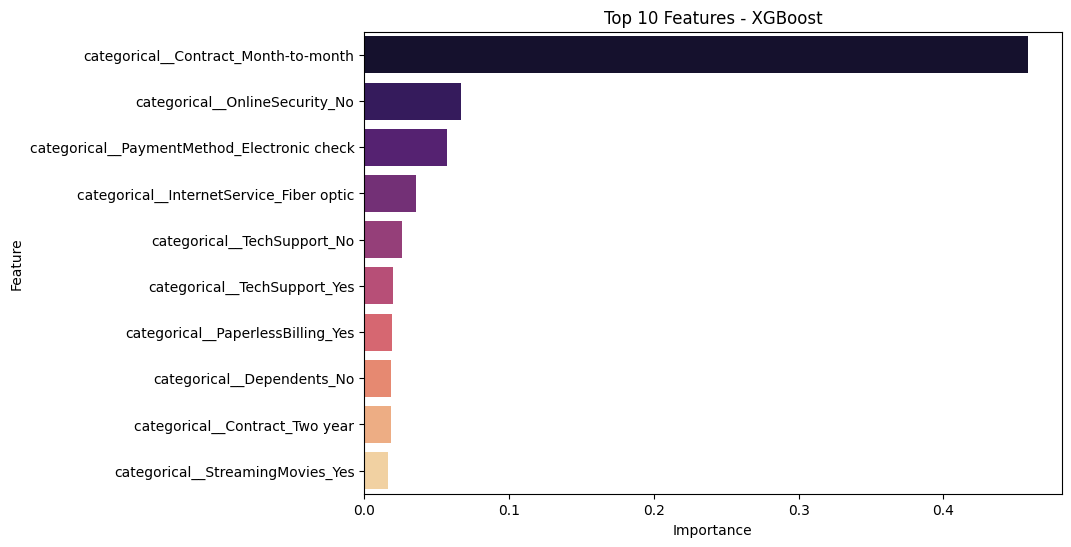

In [40]:

xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print("XGBoost - Top 10 Features")
display(xgb_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="magma",
    legend=False
)
plt.title("Top 10 Features - XGBoost")
plt.show()

In [43]:

final_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "CV ROC-AUC": rf_cv_scores.mean(),
        "Test ROC-AUC": roc_auc_score(y_test, rf_probabilities),
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions),
        "Recall": recall_score(y_test, rf_predictions),
        "F1 Score": f1_score(y_test, rf_predictions)
    },
    {
        "Model": "XGBoost",
        "CV ROC-AUC": xgb_cv_scores.mean(),
        "Test ROC-AUC": roc_auc_score(y_test, xgb_probabilities),
        "Accuracy": accuracy_score(y_test, xgb_predictions),
        "Precision": precision_score(y_test, xgb_predictions),
        "Recall": recall_score(y_test, xgb_predictions),
        "F1 Score": f1_score(y_test, xgb_predictions)
    }
])

display(final_results.round(4))


final_results.to_csv("final_model_comparison.csv", index=False)

print("Final model comparison saved successfully!")

,Model,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8163,0.8137,0.7679,0.5601,0.5856,0.5725
1,XGBoost,0.8366,0.8301,0.7672,0.5511,0.6631,0.6019


Final model comparison saved successfully!


In [44]:
rf_importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

xgb_importance.to_csv(
    "xgboost_feature_importance.csv",
    index=False
)

print("Feature importance files saved successfully!")

Feature importance files saved successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [26]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 5.5 MB/s eta 0:00:09
   - -------------------------------------- 1.8/48.9 MB 11.1 MB/s eta 0:00:05
   --- ------------------------------------ 3.9/48.9 MB 7.8 MB/s eta 0:00:06
   --- ------------------------------------ 4.5/48.9 MB 7.3 MB/s eta 0:00:07
   ---- ----------------------------------- 5.5/48.9 MB 6.0 MB/s eta 0:00:08
   ---- ----------------------------------- 6.0/48.9 MB 5.3 MB/s eta 0:00:09
   ----- ---------------------------------- 7.1/48.9 MB 5.2 MB/s eta 0:00:09
   ----- ---------------------------------- 7.3/48.9 MB 5.1 MB/s eta 0:00:09
   ------ --------------------------------- 7.6/48.9 MB 4.7 MB/s eta 0:00:09
   ------ --------------------------------- 7.9/48.9 MB 4.1 MB/s eta 0:00:10
   ------ --------------------------------- 8.1/48.9 MB 3.7 MB/s eta 0:00:12
   ------ --------------------------------- 8.1/48.9 MB 3.7 MB/s eta 0:00:12
   --


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import xgboost

from xgboost import XGBClassifier

print("XGBoost Version:", xgboost.__version__)
print("XGBoost imported successfully!")

XGBoost Version: 3.4.1
XGBoost imported successfully!


In [20]:
%pip install imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached sklearn_compat-0.1.6-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import imblearn
from imblearn.over_sampling import SMOTENC

print("Imbalanced-learn:", imblearn.__version__)
print("SMOTENC imported successfully!")

Imbalanced-learn: 0.14.2
SMOTENC imported successfully!
